Choose a starting pension index: 100
Enter UK inflation rate for period 1 (%): 4
Enter UK average earnings growth rate for period 1(%): 2
Enter UK inflation rate for period 2 (%): 3
Enter UK average earnings growth rate for period 2(%): 5
Enter a simulation horizon for period 1 in years: 15
Enter a simulation horizon for period 2 in years: 15


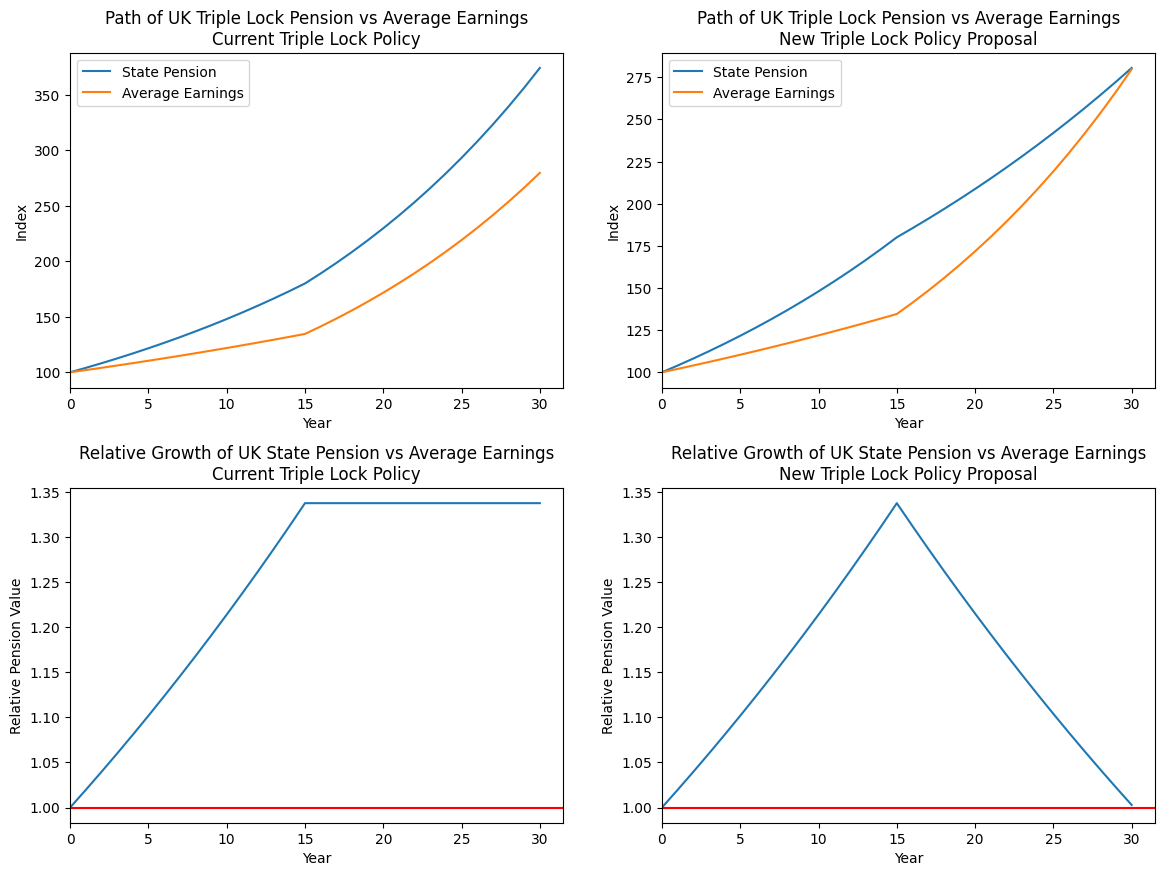

In [1]:
import matplotlib.pyplot as plt
import numpy as np

starting_pension_index = float(input("Choose a starting pension index: "))
while starting_pension_index < 100:
  starting_pension_index = float(input("Choose a new starting pension index. The number must be 100 or above: "))

old_pension_index = new_pension_index = starting_pension_index
average_earnings_index = 100

period1_inflation = float(input("Enter UK inflation rate for period 1 (%): ")) / 100
if period1_inflation <= -1:
  raise ValueError('Invalid economic scenario')
period1_average_earnings_growth = float(input("Enter UK average earnings growth rate for period 1(%): ")) / 100
if period1_average_earnings_growth <= -1:
  raise ValueError('Invalid economic scenario')
period2_inflation = float(input("Enter UK inflation rate for period 2 (%): ")) / 100
if period2_inflation <= -1:
  raise ValueError('Invalid economic scenario')
period2_average_earnings_growth = float(input("Enter UK average earnings growth rate for period 2(%): ")) / 100
if period2_average_earnings_growth <= -1:
  raise ValueError('Invalid economic scenario')
pension_rise_floor = 0.025

period1_in_years = int(input("Enter a simulation horizon for period 1 in years: "))
while period1_in_years <= 0:
  period1_in_years = int(input("Period 1 must be at least one year. Enter a new simulation horizon: "))
period2_in_years = int(input("Enter a simulation horizon for period 2 in years: "))
while period2_in_years <= 0:
  period2_in_years = int(input("Period 2 must be at least one year. Enter a new simulation horizon: "))
simulation_horizon_in_years = period1_in_years + period2_in_years
years = list(range(0, simulation_horizon_in_years + 1))

old_pension_history = [old_pension_index]
new_pension_history = [new_pension_index]
average_earnings_history = [average_earnings_index]
old_pension_relative_value_history = [old_pension_index / average_earnings_index]
new_pension_relative_value_history = [new_pension_index / average_earnings_index]

for year in range(1, simulation_horizon_in_years + 1):
  if year <= period1_in_years:
    inflation = period1_inflation
    average_earnings_growth = period1_average_earnings_growth
  else:
    inflation = period2_inflation
    average_earnings_growth = period2_average_earnings_growth
  average_earnings_index = average_earnings_index * (1 + average_earnings_growth)
  old_pension_index = old_pension_index * (1 + max(inflation, average_earnings_growth, pension_rise_floor))
  new_pension_index = max((new_pension_index * (1 + max(inflation, pension_rise_floor))), average_earnings_index)
  old_pension_relative_value = old_pension_index / average_earnings_index
  new_pension_relative_value = new_pension_index / average_earnings_index
  old_pension_history.append(old_pension_index)
  new_pension_history.append(new_pension_index)
  average_earnings_history.append(average_earnings_index)
  new_pension_relative_value_history.append(new_pension_relative_value)
  old_pension_relative_value_history.append(old_pension_relative_value)

plt.figure(figsize=(14, 10))

plt.subplot(2,2,1) #Graph for Old Pension vs Earnings
plt.plot(years, old_pension_history, label='State Pension')
plt.plot(years, average_earnings_history, label='Average Earnings')
plt.xlim(left=0)
plt.xlabel('Year')
plt.ylabel('Index')
plt.title('Path of UK Triple Lock Pension vs Average Earnings\nCurrent Triple Lock Policy')
plt.legend()


plt.subplot(2,2,2) #Graph for New Pension vs Earnings
plt.plot(years, new_pension_history, label='State Pension')
plt.plot(years, average_earnings_history, label='Average Earnings')
plt.xlim(left=0)
plt.xlabel('Year')
plt.ylabel('Index')
plt.title('Path of UK Triple Lock Pension vs Average Earnings\nNew Triple Lock Policy Proposal')
plt.legend()

plt.subplot(2,2,3) #Graph for Relative Value of Old Pension
plt.plot(years, old_pension_relative_value_history)
plt.xlim(left=0)
plt.axhline(y=1, color='red')
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.title('Relative Growth of UK State Pension vs Average Earnings\nCurrent Triple Lock Policy')

plt.subplot(2,2,4) #Graph for Relative Value of New Pension
plt.plot(years, new_pension_relative_value_history)
plt.xlim(left=0)
plt.axhline(y=1, color='red')
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.title('Relative Growth of UK State Pension vs Average Earnings\nNew Triple Lock Policy Proposal')

plt.subplots_adjust(hspace=0.3)
plt.show()
